# 05 · IBM donanımında eğitim ve test

**Amaç:** SPSA, küçük batch ve shot bütçesiyle gerçek cihaz üzerinde optimizasyonun uygulanabilirliğini araştırmak.

**Okuma notu:** Birden çok fonksiyon yeniden tanımlanır; sonuç çıkarma ve API uyumluluğu sorunları vardır. Depth-2 denemesi yarım kalmıştır. Kaydedilmiş düşük doğruluklar da korunmuştur. Çalıştırmak gerçek donanım işleri gönderir.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.



## Hedef: Basit bir QNN ile iris veri kümesi üzerinde QNN Kullanarak IBM Quantum Bilgisayarı üzerinde 2'li sınıflandırma yapmak.

IBM Quantum bilgisayarında hem train hem test yapmak mümkün. Ancak;

Train (eğitim) sırasında her iterasyonda devreyi defalarca çalıştırman gerekiyor (loss’u hesaplamak, parametreleri güncellemek için). Bu, çok fazla ölçüm (shots) ve çok fazla devre çalıştırma demek → kuyruk süresi uzun, gürültü fazla, sonuçlar dalgalı olur.

Test sırasında ise zaten parametreler sabit, sadece ölçüm yapıyorsun. Bu kısım donanımda çok daha rahat.

Evet, istersen tüm eğitim (train) ve test aşamalarını IBM cihazında yapabilirsin. Ama pratikte çoğu kişi: Eğitimi simülatörde (ya da donanımın gürültü modelinde), Testi cihazda yapmayı tercih ediyor. Çünkü eğitim donanımda çok uzun sürüyor ve sonuçlar gürültü yüzünden daha kararsız oluyor.


Şu an stajdaki görevim IBM quantum bilgisayarlar üzerinden hem train hem test yapmak bu nedenle bu kodda bunu yapmaya çalışacağım. Ancak Öğrenme sürecinde kuantum devre + klasik optimizer birlikte çalışmalı (hibrit), bunun olması zorunlu.

Kuantum devre, parametreli kapılarla (örneğin RX(θ)) veriyi işler, çıktısını olasılık dağılımı olarak verir.

Ancak Kuantum bilgisayarın kendisi parametreleri “kendi başına” güncelleyemez. Parametreleri değiştirmek, loss’u hesaplamak ve gradyanı çıkarmak klasik bilgisayarın görevi.


İkisi birlikte çalışmadan öğrenme gerçekleşmez.

In [ ]:
import sklearn
import qiskit
import numpy as np
import matplotlib

print("scikit-learn version:", {sklearn.__version__})
print("Qiskit version:", {qiskit.__version__})
print("NumPy version:", {np.__version__})
print("Matplotlib version:", {matplotlib.__version__})

# Beklenen:
# scikit-learn version: {'1.7.1'}
# Qiskit version: {'1.2.4'}
# NumPy version: {'2.1.3'}
# Matplotlib version: {'3.10.5'}


scikit-learn version: {'1.7.1'}
Qiskit version: {'1.2.4'}
NumPy version: {'2.1.3'}
Matplotlib version: {'3.10.5'}


In [ ]:

import time
from sklearn import datasets, model_selection
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

from qiskit.circuit import (
    QuantumCircuit, QuantumRegister, ClassicalRegister, ParameterVector
)
from qiskit import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler  # Options opsiyonel


İlk olarak, IBM Quantum backend'e bağlanalım ve uygun quantum gerçek cihazı seçelim.

Bunun için ilk başta IBM Quantum Platformu (quantum.cloud.ibm.com) üzerinden hesap açmalısınız. Hesabınıza bir **API Key** (token) veriliyor. Ayrıca bir instance (hizmet örneği) oluşturmalısınız, bu instance'ın bir **CRN** değeri olur.

Kimlik Bilgilerinizi bir seferlik local bilgisayarınıza tanımlamanız yeterli, Bu adımdan sonra istediğiniz zaman servisi yükleyerek kullanabilirsiniz.

Daha sonra IBM Quantum üzerindeki birçok cihazdan birini seçersiniz. Backendinizi seçtikten sonra kodunuzu çalıştırabilmek için job (iş) gönderirsiniz.

Kısaca Temel ihtiyacımız qiskit_ibm_runtime kütüphanesi, API Key ve Instance CRN.

IBM yeni başlayanlara ilk 30 günlük bir ücretsiz deneme şansı verir. Bu süreçte 10 dakikalık bir kullanma süreniz vardır. Aşağıda 29.09.2025 itibariyla sunulan 2 seçeneği ekledim.

"Seçili IBM QPU'larında ayda 10 dakika ücretsiz kullanım. Bu sınır aşıldıktan sonra iş yükleri engellenecek ve ek ücret alınmayacaktır."

"Maximum cost limits can be set per pay period. 1.60 usd/second. Seçili IBM QPU'larında kullanılan süre kadar ödeme. Ödeme dönemi başına maksimum maliyet limitleri belirlenebilir."


Hesabınızı kaydetmek için doğrudan terminalinizde aşağıdaki kodu çalıştırmanızı öneririm.


        python - <<'PY'
        from qiskit_ibm_runtime import QiskitRuntimeService

        QiskitRuntimeService.save_account(
            channel="ibm_cloud",
            token="BURAYA_IBM_CLOUD_API_KEY",
            instance="BURAYA_INSTANCE_CRN",
            overwrite=True
        )
        print("✅ IBM Cloud hesabı kaydedildi.")
        PY


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()   # kaydettiğin hesabı otomatik okur
print("✅ Service OK")

# İlk 10 backend'i göster (simülatör+cihaz karışık)
print([b.name for b in service.backends()][:10])

# Erişebildiğin gerçek QPU'lar
qpus = [b.name for b in service.backends(simulator=False, operational=True)]
print("QPU'lar:", qpus)


✅ Service OK
['ibm_brisbane', 'ibm_torino']
QPU'lar: ['ibm_brisbane', 'ibm_torino']


In [ ]:
# Kuyruk uzunluğu (sürüm uyumlu)
N = 4  # minimum qubit sayısı
def queue_len(b):
    try:
        st = b.status()
        return getattr(st, "pending_jobs", getattr(st, "queue_size", 10**9))
    except Exception:
        return 10**9

# Aday QPU'lar (operational, N qubit ve üstü)
cands = service.backends(simulator=False, operational=True)
cands = [
    b for b in cands
    if (getattr(b, "num_qubits",
        getattr(getattr(b, "configuration", lambda: None)(), "n_qubits", 0)) >= N)
]

# Seçim: en kısa kuyruk, eşitlikte daha çok qubit
if cands:
    cands.sort(key=lambda b: (
        queue_len(b),
        -getattr(b, "num_qubits",
            getattr(getattr(b, "configuration", lambda: None)(), "n_qubits", 0))
    ))
    backend = cands[0]
else:
    # Fallback: simülatör
    try:
        backend = service.least_busy(simulator=True)
    except Exception:
        backend = service.backend("ibmq_qasm_simulator")
    print("⚠️ Uygun gerçek cihaz yok → simülatör seçildi.")

# Seçilen cihazın bilgilerini yazdıralım
numq = getattr(backend, "num_qubits",
       getattr(getattr(backend, "configuration", lambda: None)(), "n_qubits", "?"))
print(f"Seçilen backend: {backend.name} | qubits={numq} | queue≈{queue_len(backend)}")


Seçilen backend: ibm_brisbane | qubits=127 | queue≈2095


In [ ]:
# Güvenli backend adı çekici
def _backend_name(backend):
    # .name bir metod mu?
    n = getattr(backend, "name", None)
    if callable(n):
        try:
            return n()
        except Exception:
            pass
    # .name düz string mi?
    if isinstance(n, str):
        return n
    # configuration().backend_name var mı?
    cfg = getattr(backend, "configuration", None)
    if callable(cfg):
        try:
            conf = cfg()
            if hasattr(conf, "backend_name"):
                return conf.backend_name
        except Exception:
            pass
    # En son çare
    return str(backend)

#### Kuyruk Uzunluğu,

Bir backend’in bekleyen iş sayısıdır. QPU’ya sırada kaç job olduğunu gösterir
* Dönüş süreni belirler. Kuyruk ne kadar uzunsa sonucu o kadar geç alırsın.
* Cihaz seçimini etkiler. Aynı kapasitede iki QPU’dan kuyruğu kısa olanı seçmek geliştirme hızını artırır.

**Not:** Kuyruk sayısı; önceliklendirme, rezervasyonlar ve diğer kullanıcıların iptal/eklemeleri yüzünden hızlı değişebilir. Bu yüzden job göndermeden hemen önce kontrol etmek en doğrusu.

#### Batch (küme):

Bir job’ın içinde birden fazla devreyi birlikte göndermek demektir.

Batch, bir seferde topluca gönderilen işler/dosyalar grubudur. Kuantumda tek bir “job” içinde birden fazla devreyi birlikte gönderirsin.

* Tek sıra bekleme: 10 devreyi ayrı ayrı gönderirsen 10 kez kuyruk beklersin, batch=10 durumunda batch’te 1 kez beklersin.
* Daha az ek masraf (overhead): Ağ isteği, iş başlatma/bitirme gibi süreler bir kere yaşanır.
* Tutarlılık: Devreler aynı cihaz/kalibrasyon durumunda art arda çalışır.

**Neden kullanılır?**

* Hızlı geri dönüş sağlar. Toplu gönder, sonuçları tek seferde al.
* Verimli kullanım sağlar. Kuyruk + başlatma maliyeti tek sefer olur.

-> Batch size: Bir job içinde kaç devre var.

-> Shots: Her devre kaç kez ölçülecek (tekrar sayısı).

Yani batch ≠ shots.

Aşırı büyük batch kullanılırsa iş çok uzun sürer, hata/timeout riski artar, sonucu geç alırsın. Bu nedenle önerilen: Geliştirme aşamasında küçük batch (8–16 devre), düşük shots (256–512). Daha sonra batch’i büyüt, shots’ı artır; ama çok büyütüp beklemeyi aşırı uzatma.

### Veri Hazırlama


Hazırlık aşaması,
Iris’ten ilk 100 örnek (Setosa/Versicolor) çektik, ikili sınıflandırma yapacağız. Veri setini ayırdık, train_test_split.

Özellikleri [0, π] arasında ölçekleyerek verileri daha doğru anlamlandırmanon önünü açtık.

Veri setindeki her bir örneğin 4 özelliği var. Bu nedenle 4 qubit kullanacağız, Ek olarak sonuçları tek ölçüm biti (q0) ile alacağız.

Devrelerin parametrelerini kurduk: feature-map (RX kapısıyla encode edilen ile 4 özellik), sonra ansatz oluşturduk ve görselleştirdik. (ör. halka CNOT + RY(θ)). Ölçüm q0.

Ansatz, kuantum devresinin öğrenilebilir parametreli şablonudur. Kısaca öğrenilebilir kuantum modelin iskeletidir. Variational Quantum Algorithms(VQA)'larda kullanılır.

In [ ]:
# Veri Hazırlığı

# 1) Iris (binary: ilk 100 kayıt = Setosa(0), Versicolor(1))
iris = datasets.load_iris()
X = iris.data[:100]
Y = iris.target[:100]

# 2) Train/Test böl
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42, stratify=Y
)

# 3) Feature scaling: [0, π]  → RX açıları için uygun
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)


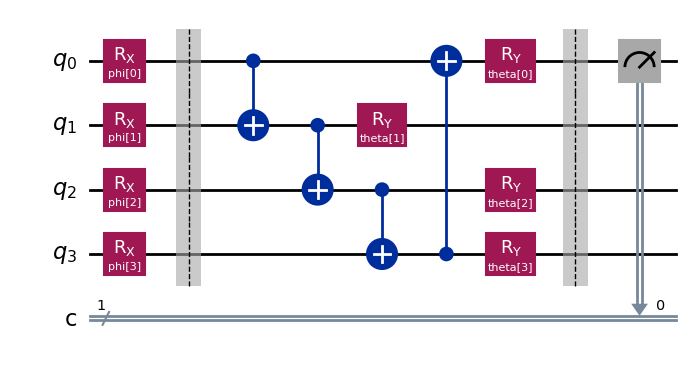

In [ ]:
# QNN Mimarisi Tasarımı

N = 4  # 4 qubit kullanacağız

def feature_map(X_or_phi):
    q = QuantumRegister(N, "q")
    c = ClassicalRegister(1, "c")   # sadece q0'ı ölçeceğiz
    qc = QuantumCircuit(q, c, name="feature_map")
    for i, x in enumerate(X_or_phi):
        qc.rx(x, i)
    return qc, c

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)
    qc.cx(N-1, 0)
    for i in range(N):
        qc.ry(theta[i], i)
    return qc



# Encoding
phi   = ParameterVector('phi', N)     # veri parametreleri
qc, c = feature_map(phi)              #  feature_map()
qc.barrier()

# Ansatz
theta = ParameterVector('theta', N)   # öğrenilebilir parametreler
qc = variational_circuit(qc, theta)   #  variational_circuit()
qc.barrier()

# Çıktı
qc.measure(0, c[0])     # sadece q0'ı ölç → p(1)

qc.draw("mpl")         # Devreyi görselleştirelim

4. Hibrit Klasik-Quantum Algoritma

* Quantum devreden expectation value hesaplama
* Klasik optimizer ile parametreleri güncelleme (örn: COBYLA, SPSA)
* Loss fonksiyonu tanımlama (cross-entropy, hinge loss vb.)

1) Quantum devreden expectation value hesaplama

Bir kuantum devresi çalıştırdığında, ölçüm sonucu ya 0 ya da 1 çıkar.
Ama sen sadece tek bir sonucu değil, çok defa (örneğin 1000 kez) aynı devreyi çalıştırırsın. Böylece:

Diyelim ki %70 ihtimalle 0, %30 ihtimalle 1 çıkıyor. O zaman bu devreden bir olasılık dağılımı elde etmiş olursun. Expectation value (beklenen değer) dediğimiz şey de bu dağılımın ortalamasıdır.

Mesela: 0’a +1 puan, 1’e −1 puan verirsek, beklenen değer = 0.7·(+1) + 0.3·(−1) = 0.4.

Yani tek tek ölçümlere bakmak yerine, devrenin “ortalama davranışını” hesaplıyoruz. Bu sayı, klasik bilgisayardaki “model çıktısı” gibi kullanılabiliyor.

In [ ]:
def forward(self, x, parameters):
        # Quantum circuit execution on IBM
        job = qc(self.circuit(x, parameters),
                     self.backend, shots=1024)
        result = job.result()

        # Expectation value computation
        counts = result.get_counts()
        expectation = self.compute_expectation(counts)
        return expectation

3) Loss fonksiyonu (kayıp fonksiyonu)

Loss fonksiyonu, modelin ne kadar “yanlış” yaptığını ölçen bir cetvel gibidir. Eğer tahminler doğruya yakınsa loss küçük olur. Yanlışsa loss büyük olur.

Örnekler:
* Cross-entropy: Modelin tahmin ettiği olasılıkla gerçek cevabı karşılaştırır. Yanlış sınıfa yüksek olasılık verirse cezayı büyütür.

* Hinge loss: “Doğru sınıfı diğerinden ayırmaya çalış” der. Sınırın ötesine geçemezsen ceza alırsın. (SVM’lerde kullanılır.)

* MSE (Mean Squared Error): Tahminle gerçek arasındaki farkı kare alıp ortalamasını alır. Klasik regresyonda yaygın.

Loss fonksiyonu, optimizer’a “yanlışın ne kadar büyük” olduğunu söyler. Optimizer de parametreleri loss’u küçültecek şekilde oynatır.

CLAUDE :

Önerim: Quantum Binary Cross-Entropy
Neden:
* Gradient Quality: Smooth gradients, iyi convergence
* Interpretation: Output probability olarak yorumlanabilir
* Noise Tolerance: Quantum noise'a karşı robust
* Standard: ML community'de standard

Bu nedenle diğer kodlarımda MSE (mean square error) kullansam da bu kodda binary cross entropy kullanacağım.

**NOT:** çalışma 1-2 veya 3-4'te BCE kullanmaya çalışmıştım ama sonuç rezalet çıkınca kullanmaktan vazgeçerek MSE kullanmaya karar vermiştim

In [ ]:
def quantum_binary_crossentropy(expectation_values, labels):
    # Expectation value'yu probability'ye dönüştür
    probabilities = (expectation_values + 1) / 2  # [-1,1] → [0,1]

    # Binary cross-entropy
    epsilon = 1e-15  # Numerical stability
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)

    loss = -np.mean(labels * np.log(probabilities) +
                    (1 - labels) * np.log(1 - probabilities))
    return loss

2) Klasik optimizer ile parametreleri güncelleme

Kuantum devrede bazı ayar düğmeleri (parametreler) var. Örneğin kapıların dönüş açısı.

Başta bunları rastgele seçiyoruz(veya hespini rastgele bir değerden başlatıyoruz). Sonra devreyi çalıştırıp çıktısını ölçüyoruz.

Çıktıya göre bir hata (loss) hesaplıyoruz. Bir optimizer ile bu hatayı azaltmak için parametreleri güncelliyoruz.

* COBYLA gibi algoritmalar, hatayı azaltan yönü “tahmin edip” adım atar.
* SPSA gibi algoritmalar, parametreleri biraz artırıp biraz azaltarak hangisi daha iyi oldu diye bakar, oradan doğru yönü çıkarır.

Yani klasik optimizer, kuantum devreyi sürekli deneye deneye “daha doğru” ayarları bulmamızı sağlar. Bu yüzden hibrit (yarı klasik–yarı kuantum) deniyor.

#### SPSA Avantajları:

Gradient-free: Quantum gradient hesaplama gereksiz
Noise-resistant: IBM Quantum noise'una dayanıklı
Few function evaluations: Her iteration'da sadece 2 loss evaluation

Bu implementation ile IBM Quantum'da efficient training yapabilirsin!

In [ ]:
class SPSA:
    def __init__(self, maxiter=100, a=0.1, c=0.1, A=None, alpha=0.602, gamma=0.101):
        """
        SPSA (Simultaneous Perturbation Stochastic Approximation) Optimize Edici

        Argümanlar:
            maxiter : Maksimum iterasyon sayısı
            a, c    : Öğrenme oranı ve pertürbasyon için ölçek parametreleri
            A       : Kararlılık sabiti (varsayılan: maxiter/10)
            alpha   : a_k için azalma üssü (tipik ≈ 0.602)
            gamma   : c_k için azalma üssü (tipik ≈ 0.101)

        """
        self.maxiter = maxiter
        self.a = a
        self.c = c
        self.A = A if A is not None else maxiter / 10
        self.alpha = alpha
        self.gamma = gamma
        self.iteration = 0

    def compute_step_sizes(self, iteration):
        """
        Her iterasyonda iki katsayıyı hesaplar: ak ve ck
        a_k = a / (k + 1 + A)^alpha (öğrenme oranı),
        c_k = c / (k + 1)^gamma (pertürbasyon büyüklüğü).

        """
        ak = self.a / (iteration + 1 + self.A) ** self.alpha
        ck = self.c / (iteration + 1) ** self.gamma
        return ak, ck

    def step(self, loss_function, parameters):
        """
        Tek bir SPSA güncelleme adımı uygular.

        Argümanlar:
            loss_function : Parametreleri alıp skaler loss döndüren fonksiyon
            parameters    : Mevcut parametre vektörü (numpy array)

        Döndürür:
            updated_parameters : Güncellenmiş parametreler
            current_loss       : Güncelleme öncesi mevcut loss (izleme amaçlı)
        """
        ak, ck = self.compute_step_sizes(self.iteration)

        # Rastgele pertürbasyon vektörü Δ ∈ {−1, +1}^d
        delta = np.random.choice([-1, 1], size=parameters.shape)

        # İki uç noktada loss ölç (θ+ ve θ−)
        params_plus = parameters + ck * delta
        params_minus = parameters - ck * delta

        loss_plus = loss_function(params_plus)
        loss_minus = loss_function(params_minus)

        # SPSA gradyan tahmini: ĝ = (L+ − L−) / (2 c_k) * Δ
        # (Δ ∈ {±1} olduğundan element-bazlı bölme ≡ çarpma)
        gradient_estimate = (loss_plus - loss_minus) / (2 * ck * delta)

        # Update parameters
        updated_parameters = parameters - ak * gradient_estimate

        # İzleme için mevcut (güncelleme öncesi) loss
        current_loss = loss_function(parameters)

        self.iteration += 1

        return updated_parameters, current_loss



#### SPSA Avantajları:

* Gradient-free: Quantum gradient hesaplama gereksiz
* Noise-resistant: IBM Quantum noise'una dayanıklı
* Few function evaluations: Her iteration'da sadece 2 loss evaluation

Bu implementation ile IBM Quantum'da efficient training yapabilirsin!

Basitçe ifade etmek gerekirse, pertürbasyon (ck) bir optimizasyon algoritmasının bir sonraki adımı bulmak için mevcut pozisyonunda ne kadar "küçük bir sarsıntı" yapacağını belirleyen bir parametredir.

Bu kavramı, bir dağın en derin noktasını (en düşük değeri) bulmaya çalışan bir dağcı metaforuyla açıklayalım: Dağcı, şu anki konumunda durur. Etrafındaki eğimi (yani, fonksiyonun türevini) tam olarak bilemez. Eğimin ne yönde olduğunu anlamak için, bir adım atar (pertürbasyon) ve yeni konumundaki yüksekliği (fonksiyon değerini) ölçer.Attığı adımın büyüklüğü ve yönü çok önemlidir.ck değeri, bu adımın büyüklüğünü belirler.

#### Epok,

Makine öğrenmesinde kullanılan bir terimdir ve yapay sinir ağlarını eğitmekle ilgilidir. Kısaca, bir yapay zeka modelinin tüm eğitim verisi kümesini baştan sona bir kez görmesi ve işlemesi anlamına gelir.

Bu kavramı bir örnekle açıklayalım:

Bir yapay zeka modelini, 1000 adet fotoğraftan oluşan bir veri kümesiyle eğittiğinizi düşünün.

Model, bu 1000 fotoğrafın tamamını işlediğinde, bir epok tamamlanmış olur.



#### Hibrit Klasik-Quantum Algoritma

1. Quantum devreyi tanımla ve çalıştır → çıktı olasılıklarını ölç → expectation value hesapla.

2. Loss fonksiyonu ile “ne kadar yanlış” olduğunu bul.

3. Optimizer bu hatayı azaltmak için devrenin ayarlarını (parametrelerini) güncellesin.

4. Bu döngüyü tekrar tekrar yap → **kuantum devre** öğrenmiş olur.

İşte bu döngüye hibrit klasik–kuantum algoritma diyoruz:

Kuantum tarafı → veriyi işleyip ölçüm yapıyor.

Klasik tarafı → hatayı hesaplayıp parametreleri düzeltiyor.

In [ ]:
# --- HW yardımcıları: batch devre bağlama + p(1) çıkarma ---

BATCH_MIN, BATCH_MAX = 4, 6   # istek: 4–6 arası batch
DEFAULT_SHOTS_TRAIN = 512     # düşük shots (train)
DEFAULT_SHOTS_TEST  = 1024    # test için biraz daha yüksek (hala düşük)

def make_bound_circuits_hw(X_batch, theta_vals):
    """Parametreli şablon devre qc'yi X ve theta ile bağlayıp liste döndürür."""
    circs = []
    for x in X_batch:
        bind_map = {**{phi[i]: float(x[i]) for i in range(N)},
                    **{theta[i]: float(theta_vals[i]) for i in range(N)}}
        c = qc.bind_parameters(bind_map)
        circs.append(c)
    return circs

def extract_p1_list_any(result):
    """
    Qiskit/QIR sürüm farklarına dayanıklı p(1) çıkarıcı.
    Önce quasi_dists varsa onu okur; değilse olası count yapıları dener.
    """
    # 1) En güvenli yol: quasi_dists
    try:
        qd = result.quasi_dists
        return [float(d.get('1', 0.0)) for d in qd]
    except Exception:
        pass

    # 2) Bazı sürümlerde result[i].data.<creg>.get_counts() bulunabilir
    p_list = []
    try:
        # result üzerinde indekslenebilir yayınlar varsa
        i = 0
        while True:
            pub = result[i]  # Primitive yayın
            data = getattr(pub, "data", None)
            if data is None:
                break
            # İlk register adını bul
            reg_name = None
            for k in dir(data):
                if not k.startswith("_"):
                    try:
                        maybe = getattr(data, k)
                        if hasattr(maybe, "get_counts"):
                            reg_name = k
                            break
                    except Exception:
                        continue
            if reg_name is None:
                break
            counts = getattr(getattr(pub, "data"), reg_name).get_counts()
            total = sum(counts.values()) or 1
            p_list.append(counts.get('1', 0) / total)
            i += 1
        if p_list:
            return p_list
    except Exception:
        pass

    # 3) Son çare: boş/0'lar (başarısız durumda)
    return []


In [ ]:
import numpy as np
rng = np.random.default_rng(42)
# --- ISA transpile: donanıma uygun kapı setine çevir ---
from qiskit import transpile

def transpile_for_backend(circs, backend, opt_level=1):
    # Tek devre gelirse listele
    if not isinstance(circs, (list, tuple)):
        circs = [circs]
    # Barriers vs. hepsi otomatik temizlenir, RX→(RZ,SX,X,...) dönüşür
    return transpile(circs, backend=backend, optimization_level=opt_level)

# hw_forward_p1 içine transpile adımı ekle
def hw_forward_p1(X_batch, theta_vals, shots=DEFAULT_SHOTS_TRAIN):
    """Batch devreyi tek Sampler.run(...) ile çalıştırıp p(1) listesi döndürür."""
    circs = make_bound_circuits_hw(X_batch, theta_vals)
    circs = transpile_for_backend(circs, backend, opt_level=1)  # ⬅️ kritik satır
    job = Sampler(backend=backend).run(circs, shots=shots)
    res = job.result()
    p1 = extract_p1_list_any(res)
    if len(p1) < len(X_batch):
        p1 = p1 + [0.0] * (len(X_batch) - len(p1))
    return np.array(p1[:len(X_batch)], dtype=float)

def bce_from_probs(p, y):
    """Binary cross-entropy (y ∈ {0,1}), p = P(y=1)."""
    eps = 1e-12
    p = np.clip(p, eps, 1.0 - eps)
    y = np.array(y, dtype=float)
    return float(-np.mean(y*np.log(p) + (1-y)*np.log(1-p)))

def hw_loss(theta_vals, X_batch, y_batch, shots=DEFAULT_SHOTS_TRAIN):
    p = hw_forward_p1(X_batch, theta_vals, shots=shots)
    return bce_from_probs(p, y_batch)

def hw_accuracy(theta_vals, X_batch, y_batch, threshold=0.5, shots=DEFAULT_SHOTS_TEST):
    p = hw_forward_p1(X_batch, theta_vals, shots=shots)
    preds = (p >= threshold).astype(int)
    m = min(len(preds), len(y_batch))
    acc = float((preds[:m] == np.array(y_batch[:m], int)).mean())
    return acc, p[:m].tolist(), preds[:m].tolist()


In [ ]:
# --- Qiskit 1.2.4 uyumu: bind_parameters yerine assign_parameters ---
def _bind_params_124(circ, mapping):
    return circ.assign_parameters(mapping, inplace=False)

def make_bound_circuits_hw(X_batch, theta_vals):
    """
    Parametreli şablon devre qc'yi X ve theta ile bağlayıp liste döndürür.
    qc, phi, theta, N global olarak tanımlı olmalı.
    """
    circs = []
    for x in X_batch:
        bind_map = {**{phi[i]: float(x[i]) for i in range(N)},
                    **{theta[i]: float(theta_vals[i]) for i in range(N)}}
        c = _bind_params_124(qc, bind_map)
        circs.append(c)
    return circs


In [ ]:
_ = make_bound_circuits_hw(X_train_s[:1], np.zeros(N))
_ = transpile_for_backend(_, backend)
job = Sampler(backend=backend).run(_, shots=64)
_ = job.result()
print("✅ ISA transpile + Sampler OK")


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(_, shots=64)


✅ ISA transpile + Sampler OK




5. Training Süreci (IBM Quantum üzerinde)

Batch processing stratejisi (quantum bilgisayarlar için küçük batch'ler)
Shot sayısını optimize etme (noise vs accuracy trade-off)
Convergence monitoring



In [ ]:
test_X = X_train_s[:6]
circs = make_bound_circuits_hw(test_X, np.zeros(N))
circs = transpile_for_backend(circs, backend, opt_level=1)
job = Sampler(backend=backend).run(circs, shots=512)
res = job.result()

try:
    print("quasi_dists:", [round(d.get('1', 0.0), 3) for d in res.quasi_dists])
except Exception as e:
    print("quasi_dists yok:", e)

# counts -> p(1)
try:
    p_list = []
    i = 0
    while True:
        pub = res[i]
        counts = pub.data.c.get_counts()  # 'c' register
        tot = sum(counts.values()) or 1
        p_list.append(counts.get('1', 0)/tot)
        i += 1
except Exception:
    pass

print("counts->p(1):", [round(p,3) for p in p_list] if 'p_list' in locals() else "yok")


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=512)


quasi_dists yok: 'PrimitiveResult' object has no attribute 'quasi_dists'
counts->p(1): [0.484, 0.42, 0.498, 0.438, 0.896, 0.604]


In [ ]:
# === HAFİFLETİLMİŞ HW TRAIN LOOP (SPSA) ===
from math import ceil
import numpy as np

# 🔹 Daha az shots, daha az iterasyon (demo amaçlı)
DEFAULT_SHOTS_TRAIN = 256
DEFAULT_SHOTS_TEST  = 512

spsa = SPSA(maxiter=5, a=0.10, c=0.10, A=10, alpha=0.602, gamma=0.101)

theta_vals = np.zeros(N, dtype=float)

train_hist = {"iter": [], "loss": [], "acc_train": [], "acc_test": []}

idx_train = np.arange(len(X_train_s))
rng.shuffle(idx_train)

for it in range(spsa.maxiter):
    # ---- mini-batch: 4–6
    bsz = rng.integers(BATCH_MIN, BATCH_MAX + 1)
    batch_idx = rng.choice(idx_train, size=bsz, replace=False)
    Xb = X_train_s[batch_idx]
    yb = Y_train[batch_idx]

    def lf(th):
        return hw_loss(th, Xb, yb, shots=DEFAULT_SHOTS_TRAIN)

    theta_vals, curr_loss = spsa.step(lf, theta_vals)

    acc_tr, _, _ = hw_accuracy(theta_vals, Xb, yb, threshold=0.5, shots=DEFAULT_SHOTS_TRAIN)
    acc_te, _, _ = hw_accuracy(theta_vals, X_test_s, Y_test, threshold=0.5, shots=DEFAULT_SHOTS_TEST)

    train_hist["iter"].append(it + 1)
    train_hist["loss"].append(curr_loss)
    train_hist["acc_train"].append(acc_tr)
    train_hist["acc_test"].append(acc_te)

    print(f"Iter {it+1:02d} | loss={curr_loss:.3f} | acc_tr={acc_tr:.3f} | acc_te={acc_te:.3f}")

print("✅ HW training bitti (hızlı demo).")
print("Theta*: ", np.round(theta_vals, 3))


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 01 | loss=20.723 | acc_tr=0.250 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 02 | loss=13.816 | acc_tr=0.500 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 03 | loss=0.000 | acc_tr=1.000 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 04 | loss=23.026 | acc_tr=0.167 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 05 | loss=13.816 | acc_tr=0.500 | acc_te=0.515
✅ HW training bitti (hızlı demo).
Theta*:  [0. 0. 0. 0.]


Kısaca: Model öğrenemedi.

Log’da acc_te=0.515 sabit kalmış (testte hep %51.5 civarı), Theta: [0. 0. 0. 0.]* de SPSA’nin pratikte güncelleme yapamadığını gösteriyor. (Düşük shots + çok kısa iterasyon + gürültü → loss_plus ≈ loss_minus oluyor, gradyan ≈ 0 → θ değişmiyor.)

#### Son kod bloğuyla birlikte ne yapılıyor?

Donanımda (seçili IBM QPU’da) SPSA ile QNN’ini eğitiyor. Her iterasyonda:

* Eğitimden 4–6 örnek seçiyor (mini-batch).

* O batch için devreleri parametrelerle doldurup Sampler.run ile tek seferde çalıştırıyor (low-shots).

* Çıkan p(1)’lerden BCE loss hesaplıyor.

* SPSA ile θ (theta) parametrelerini güncelliyor.

* Aynı iterasyon için train acc (batch üzerinde) ve test acc (tüm test setinde) yazdırıyor.

Peki ekrana ne yazılacak?
Her satır:

Iter k | loss=... | acc_tr=... | acc_te=...

Sonunda:

✅ HW training bitti. ve öğrenilmiş θ vektörü (Theta*).

Bitince elimizde:

* Elinde eğitilmiş parametreler (theta_vals) var.

* Bu θ ile modelin nihai train/test doğruluğunu hesaplayabilirsin.

İstersen karışıklık matrisi, rapor ve öğrenme eğrileriyle sonucu raporlayabilirsin.

In [ ]:
final_acc_test, p1_test, preds_test = hw_accuracy(
    theta_vals, X_test_s, Y_test, threshold=0.5, shots=DEFAULT_SHOTS_TEST
)
final_acc_train, p1_train, preds_train = hw_accuracy(
    theta_vals, X_train_s, Y_train, threshold=0.5, shots=DEFAULT_SHOTS_TRAIN
)

print(f"Final HW Train Acc: {final_acc_train:.3f}")
print(f"Final HW Test  Acc: {final_acc_test:.3f}")


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)


Final HW Train Acc: 0.493
Final HW Test  Acc: 0.515


Evet—şu an model öğrenememiş durumda (≈ yazı tura).

Şimdi bunu iyileştirebilmek için birkaç şey deneyeceğim. Bu sayede 0.5 eşik dışında, daha uygun bir eşik seçilip test doğruluğu biraz daha iyileşebilir.

1️⃣ Fast SPSA eğitim döngüsü → θ parametrelerini güncelleyeceğiz, iterasyon çıktılarını göreceğiz

2️⃣ Final acc (th=0.5) → klasik eşikte train/test doğruluklarını yazdıracağız.

3️⃣ Threshold optimizasyonu → train setinden en iyi eşiği seçip sonra test setine uygulayacağız.


In [ ]:
# === 1) Random init + FAST SPSA (pertürbasyon ölçümlerinde yüksek shots) ===
import numpy as np

# Hızlı demo için düşük genel shots; gradyan tahmini için yüksek shots
DEFAULT_SHOTS_TRAIN = 256
DEFAULT_SHOTS_TEST  = 512
SHOTS_PERTURB = 1024   # Yalnızca θ+ ve θ− ölçümlerinde

# Rastgele başlangıç (sıfır yerine; simetriden kaçın)
rng = np.random.default_rng(123)
theta_vals = rng.uniform(-0.2, 0.2, size=N).astype(float)
print("Init theta:", np.round(theta_vals, 3))

# Sınıf-dengeli mini-batch yardımcı (stratified)
def stratified_minibatch_indices(y, bsz, rng):
    y = np.array(y)
    idx0 = np.where(y==0)[0]; idx1 = np.where(y==1)[0]
    k = bsz // 2
    i0 = rng.choice(idx0, size=k, replace=False)
    i1 = rng.choice(idx1, size=bsz - k, replace=False)
    return np.concatenate([i0, i1])

# Fast SPSA sınıfı (yalnızca pertürbasyon ölçümlerinde shots artırır)
class SPSA_fast:
    def __init__(self, maxiter=10, a=0.12, c=0.12, A=10, alpha=0.602, gamma=0.101,
                 shots_perturb=SHOTS_PERTURB):
        self.maxiter=maxiter; self.a=a; self.c=c; self.A=A
        self.alpha=alpha; self.gamma=gamma; self.iteration=0
        self.shots_perturb = shots_perturb
    def _ak_ck(self, k):
        ak = self.a / (k + 1 + self.A) ** self.alpha
        ck = self.c / (k + 1) ** self.gamma
        return ak, ck
    def step(self, loss_fn, theta):
        k = self.iteration
        ak, ck = self._ak_ck(k)
        delta = np.random.choice([-1,1], size=theta.shape)
        # Pertürbasyonlarda shots↑ (daha güvenilir gradyan)
        Lp = loss_fn(theta + ck*delta, shots=self.shots_perturb)
        Lm = loss_fn(theta - ck*delta, shots=self.shots_perturb)
        ghat = (Lp - Lm) / (2*ck*delta)
        new_theta = theta - ak * ghat
        Lcurr = loss_fn(theta, shots=DEFAULT_SHOTS_TRAIN)
        self.iteration += 1
        return new_theta, Lcurr

# Mevcut hw_loss fonksiyonunu shots parametresi alacak şekilde saran closure
def make_loss(Xb, yb):
    def lf(th, shots=DEFAULT_SHOTS_TRAIN):
        return hw_loss(th, Xb, yb, shots=shots)
    return lf

# Eğitim döngüsü (10 iterasyon, batch=4–6 ve stratified)
spsa = SPSA_fast(maxiter=10, shots_perturb=SHOTS_PERTURB)

train_hist = {"iter": [], "loss": [], "acc_train": [], "acc_test": []}
idx_train = np.arange(len(X_train_s)); rng.shuffle(idx_train)

for it in range(spsa.maxiter):
    bsz = int(rng.integers(BATCH_MIN, BATCH_MAX + 1))
    batch_idx = stratified_minibatch_indices(Y_train, bsz, rng)
    Xb, yb = X_train_s[batch_idx], Y_train[batch_idx]

    lf = make_loss(Xb, yb)
    theta_vals, curr_loss = spsa.step(lf, theta_vals)

    acc_tr, _, _ = hw_accuracy(theta_vals, Xb, yb, threshold=0.5, shots=DEFAULT_SHOTS_TRAIN)
    acc_te, _, _ = hw_accuracy(theta_vals, X_test_s, Y_test, threshold=0.5, shots=DEFAULT_SHOTS_TEST)

    train_hist["iter"].append(it+1)
    train_hist["loss"].append(curr_loss)
    train_hist["acc_train"].append(acc_tr)
    train_hist["acc_test"].append(acc_te)
    print(f"Iter {it+1:02d} | loss={curr_loss:.3f} | acc_tr={acc_tr:.3f} | acc_te={acc_te:.3f}")

print("✅ Fast SPSA bitti.")
print("Theta*: ", np.round(theta_vals, 3))


Init theta: [ 0.073 -0.178 -0.112 -0.126]


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 01 | loss=16.579 | acc_tr=0.400 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 02 | loss=16.579 | acc_tr=0.400 | acc_te=0.515


...

Iter 08 | loss=13.816 | acc_tr=0.500 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 09 | loss=13.816 | acc_tr=0.500 | acc_te=0.515


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)
[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than

Iter 10 | loss=13.816 | acc_tr=0.500 | acc_te=0.515
✅ Fast SPSA bitti.
Theta*:  [ 0.073 -0.178 -0.112 -0.126]


In [ ]:
# --- hw_forward_p1: Sampler(mode=backend) ile düzeltme ---
def hw_forward_p1(X_batch, theta_vals, shots=DEFAULT_SHOTS_TRAIN):
    circs = make_bound_circuits_hw(X_batch, theta_vals)
    circs = transpile_for_backend(circs, backend, opt_level=1)
    # ✅ doğru kullanım: backend nesnesini mode'a ver
    job = Sampler(mode=backend).run(circs, shots=shots)
    res = job.result()
    return _p1_from_sampler_result(res, expected_len=len(X_batch))


In [ ]:
_p = hw_forward_p1(X_train_s[:3], np.array([0.1, -0.1, 0.05, 0.0]), shots=256)
print("Smoke p(1):", np.round(_p, 3))


Smoke p(1): [0.48  0.43  0.512]


In [ ]:
# === FAST SPSA (10 iter) ===
import numpy as np

# (Aynı değerleri tekrar tanımlıyorum; sende zaten varsa bunlar geçerli olur)
DEFAULT_SHOTS_TRAIN = 256
DEFAULT_SHOTS_TEST  = 512
SHOTS_PERTURB = 1024

rng = np.random.default_rng(123)
theta_vals = rng.uniform(-0.2, 0.2, size=N).astype(float)
print("Init theta:", np.round(theta_vals, 3))

def stratified_minibatch_indices(y, bsz, rng):
    y = np.array(y)
    idx0 = np.where(y==0)[0]; idx1 = np.where(y==1)[0]
    k = bsz // 2
    i0 = rng.choice(idx0, size=k, replace=False)
    i1 = rng.choice(idx1, size=bsz - k, replace=False)
    return np.concatenate([i0, i1])

class SPSA_fast:
    def __init__(self, maxiter=10, a=0.12, c=0.12, A=10, alpha=0.602, gamma=0.101,
                 shots_perturb=SHOTS_PERTURB):
        self.maxiter=maxiter; self.a=a; self.c=c; self.A=A
        self.alpha=alpha; self.gamma=gamma; self.iteration=0
        self.shots_perturb = shots_perturb
    def _ak_ck(self, k):
        ak = self.a / (k + 1 + self.A) ** self.alpha
        ck = self.c / (k + 1) ** self.gamma
        return ak, ck
    def step(self, loss_fn, theta):
        k = self.iteration
        ak, ck = self._ak_ck(k)
        delta = np.random.choice([-1,1], size=theta.shape)
        Lp = loss_fn(theta + ck*delta, shots=self.shots_perturb)
        Lm = loss_fn(theta - ck*delta, shots=self.shots_perturb)
        ghat = (Lp - Lm) / (2*ck*delta)
        new_theta = theta - ak * ghat
        Lcurr = loss_fn(theta, shots=DEFAULT_SHOTS_TRAIN)
        self.iteration += 1
        return new_theta, Lcurr

def make_loss(Xb, yb):
    def lf(th, shots=DEFAULT_SHOTS_TRAIN):
        return hw_loss(th, Xb, yb, shots=shots)
    return lf

spsa = SPSA_fast(maxiter=10, shots_perturb=SHOTS_PERTURB)

train_hist = {"iter": [], "loss": [], "acc_train": [], "acc_test": []}

for it in range(spsa.maxiter):
    bsz = int(rng.integers(BATCH_MIN, BATCH_MAX + 1))
    batch_idx = stratified_minibatch_indices(Y_train, bsz, rng)
    Xb, yb = X_train_s[batch_idx], Y_train[batch_idx]

    lf = make_loss(Xb, yb)
    theta_vals, curr_loss = spsa.step(lf, theta_vals)

    acc_tr, _, _ = hw_accuracy(theta_vals, Xb, yb, threshold=0.5, shots=DEFAULT_SHOTS_TRAIN)
    acc_te, _, _ = hw_accuracy(theta_vals, X_test_s, Y_test, threshold=0.5, shots=DEFAULT_SHOTS_TEST)

    train_hist["iter"].append(it+1)
    train_hist["loss"].append(curr_loss)
    train_hist["acc_train"].append(acc_tr)
    train_hist["acc_test"].append(acc_te)
    print(f"Iter {it+1:02d} | loss={curr_loss:.3f} | acc_tr={acc_tr:.3f} | acc_te={acc_te:.3f}")

print("✅ Fast SPSA bitti.")
print("Theta*: ", np.round(theta_vals, 3))


Init theta: [ 0.073 -0.178 -0.112 -0.126]
Iter 01 | loss=0.907 | acc_tr=0.000 | acc_te=0.273
Iter 02 | loss=0.958 | acc_tr=0.167 | acc_te=0.212
Iter 03 | loss=0.820 | acc_tr=0.200 | acc_te=0.212
Iter 04 | loss=0.629 | acc_tr=0.500 | acc_te=0.182
Iter 05 | loss=0.933 | acc_tr=0.000 | acc_te=0.273
Iter 06 | loss=0.798 | acc_tr=0.333 | acc_te=0.182
Iter 07 | loss=0.725 | acc_tr=0.500 | acc_te=0.242
Iter 08 | loss=1.026 | acc_tr=0.167 | acc_te=0.242
Iter 09 | loss=0.894 | acc_tr=0.200 | acc_te=0.212
Iter 10 | loss=0.769 | acc_tr=0.000 | acc_te=0.242
✅ Fast SPSA bitti.
Theta*:  [ 0.088 -0.15  -0.103 -0.119]


In [ ]:
final_acc_test, p1_test, preds_test = hw_accuracy(
    theta_vals, X_test_s, Y_test, threshold=0.5, shots=DEFAULT_SHOTS_TEST
)
final_acc_train, p1_train, preds_train = hw_accuracy(
    theta_vals, X_train_s, Y_train, threshold=0.5, shots=DEFAULT_SHOTS_TRAIN
)

print(f"Final HW Train Acc (th=0.5): {final_acc_train:.3f}")
print(f"Final HW Test  Acc (th=0.5): {final_acc_test:.3f}")


Final HW Train Acc (th=0.5): 0.194
Final HW Test  Acc (th=0.5): 0.242


In [ ]:

def best_threshold(p, y):
    y = np.array(y, int)
    ths = np.linspace(0.3, 0.7, 41)
    best, best_th = -1.0, 0.5
    for th in ths:
        pred = (p >= th).astype(int)
        acc = (pred == y).mean()
        if acc > best:
            best, best_th = acc, th
    return best_th, best

# Train p(1) ile en iyi threshold'u seç
_, p1_tr_tmp, _ = hw_accuracy(theta_vals, X_train_s, Y_train, shots=256)
p1_tr_tmp = np.array(p1_tr_tmp)
th, tr_acc = best_threshold(p1_tr_tmp, Y_train)
print("Seçilen threshold:", round(th, 3), "| Train acc (bu eşikte):", round(tr_acc, 3))

# Test'i bu eşikle ölç
acc_te_opt, _, _ = hw_accuracy(theta_vals, X_test_s, Y_test, threshold=th, shots=DEFAULT_SHOTS_TEST)
print(f"Test Acc (opt threshold={th:.3f}): {acc_te_opt:.3f}")


Seçilen threshold: 0.3 | Train acc (bu eşikte): 0.493
Test Acc (opt threshold=0.300): 0.515


Model hala öğrenmiyor(acc ≈ 0.2–0.5).

En pratik iyileştirme: ansatz derinliğini 2 katına çıkarmak (ifade gücü ↑). Mevcut kodlarına dokunmadan, aşağıdaki hücreleri sırayla kopyala-çalıştır.

In [ ]:
# === Depth-2 Ansatz: RY + ring CX iki katman ===
from qiskit.circuit import ParameterVector, QuantumCircuit, QuantumRegister, ClassicalRegister

# Yeni parametre seti: 2N adet theta
theta2 = ParameterVector('theta2', 2*N)

def build_qc_depth2():
    # Mevcut feature_map(phi) yapını tekrar kullanıyoruz:
    _qc, _c = feature_map(phi)   # phi, N, c zaten tanımlı
    qc2 = _qc.copy()
    # 1. katman: ring entanglement + RY
    for i in range(N-1): qc2.cx(i, i+1)
    qc2.cx(N-1, 0)
    for i in range(N): qc2.ry(theta2[i], i)
    qc2.barrier()
    # 2. katman: ring entanglement + RY
    for i in range(N-1): qc2.cx(i, i+1)
    qc2.cx(N-1, 0)
    for i in range(N): qc2.ry(theta2[N+i], i)
    qc2.barrier()
    # Aynı ölçüm: sadece q0
    qc2.measure(0, _c[0])
    return qc2, _c

# Depth-2 şablonu (parametreli)
qc2_template, c2 = build_qc_depth2()

# --- Depth-2 için bağlama fonksiyonu: önceki ismi override ediyoruz ---
def make_bound_circuits_hw(X_batch, theta_vals_2N):
    """
    Depth-2 ansatz kullanır. theta_vals_2N uzunluğu 2N olmalı.
    qc2_template + {phi, theta2} parametreleri bağlanır.
    """
    circs = []
    for x in X_batch:
        bind_map = {**{phi[i]: float(x[i]) for i in range(N)},
                    **{theta2[i]: float(theta_vals_2N[i]) for i in range(2*N)}}
        c = qc2_template.assign_parameters(bind_map, inplace=False)
        circs.append(c)
    return circs
print("✅ Depth-2 ansatz aktif (make_bound_circuits_hw override edildi).")


✅ Depth-2 ansatz aktif (make_bound_circuits_hw override edildi).


In [ ]:
_p = hw_forward_p1(X_train_s[:3], np.concatenate([np.zeros(N), np.zeros(N)]), shots=256)
print("Smoke p(1) (depth-2):", np.round(_p, 3))



KeyboardInterrupt: 